# 🩻 Medical Chest X-Ray VQA — Google Colab Project

**Model:** `google/medgemma-1.5-4b-it` (verified on its official Hugging Face model card)
**Scope:** chest X-ray images only · inference first · optional LoRA fine-tuning at the end · no UI / API server (the code is a reusable module for your teammate's backend)

> ⚠️ **Educational / research prototype. Not a medical device.** Outputs can be wrong, are not a diagnosis, must not drive treatment decisions, and do not replace a radiologist or doctor. Use only de-identified images you are authorised to use.

### Facts checked against the official model card before writing this notebook
| Item | What the model card says |
|---|---|
| Repo ID | `google/medgemma-1.5-4b-it` (MedGemma 1.5 exists only as a 4B multimodal instruction-tuned model) |
| Inputs / outputs | Text + images in, **text only** out. Images are normalised to 896×896 (256 tokens each) |
| Access | Repo is *gated*: you must log in to Hugging Face and accept the **Health AI Developer Foundations (HAI-DEF) terms of use** |
| Loading | `AutoModelForImageTextToText` + `AutoProcessor`, `torch_dtype=torch.bfloat16`, `processor.apply_chat_template(...)`, `transformers ≥ 4.50.0` |
| Limits | "Not evaluated or optimized for **multi-turn** applications"; "more sensitive to the specific prompt than Gemma 3"; safety evaluation "included primarily English language prompts"; outputs "not intended to directly inform clinical diagnosis" |
| Training data (relevant to leakage) | Includes MIMIC-CXR, Chest ImaGenome, SLAKE and others — so scores on those public sets can overstate real generalisation |

### Honest note about this notebook
I (the assistant that wrote it) could not run it against the real model — it needs a Colab GPU and your Hugging Face access. The code follows the official card and has been syntax-checked, but **run it cell by cell and report any error you hit; do not assume it works until the outputs in each cell match the "expected output"**. Hindi/Hinglish quality is *tested here, not assumed*.

### How to use
1. `Runtime → Change runtime type → GPU` (T4 is the free option; availability is **not guaranteed** and sessions can disconnect — that is why we save to Drive).
2. Run cells **in order, top to bottom**.
3. Steps 0–7 get one X-ray + one question working. Everything after that is optional/extended.

---

## Step 1 — Environment check (GPU, RAM, disk)

**Purpose:** confirm a GPU exists and decide whether the 4B model fits in memory *before* downloading ~8.6 GB.
**Expected output:** a GPU name (e.g. `Tesla T4`), ~15 GB GPU memory, and a verdict line.
**Common errors**
- `No GPU detected` → `Runtime → Change runtime type → T4 GPU`, then `Runtime → Restart session` and rerun.
- GPU memory already mostly used → `Runtime → Disconnect and delete runtime`, then reconnect.
- If the verdict says **4-bit recommended**, the later load cell will use it automatically (needs `bitsandbytes`, installed in Step 2).

In [ ]:
import os, sys, shutil, platform, subprocess
import psutil, torch

GB = 1024 ** 3
print(f"Python  : {sys.version.split()[0]} | {platform.platform()}")
print(f"PyTorch : {torch.__version__}")

ram = psutil.virtual_memory()
print(f"System RAM : {ram.total/GB:.1f} GB total, {ram.available/GB:.1f} GB available")
du = shutil.disk_usage("/content")
print(f"Disk (/content): {du.total/GB:.0f} GB total, {du.free/GB:.0f} GB free")

HAS_GPU = torch.cuda.is_available()
GPU_FREE_GB = 0.0
RECOMMEND_4BIT = False
NATIVE_BF16 = False

if not HAS_GPU:
    print("\n❌ No GPU detected. Switch runtime to a GPU (Runtime → Change runtime type), restart, rerun this cell.")
else:
    props = torch.cuda.get_device_properties(0)
    free_b, total_b = torch.cuda.mem_get_info()
    GPU_FREE_GB = free_b / GB
    NATIVE_BF16 = props.major >= 8
    print(f"GPU : {props.name} | compute capability {props.major}.{props.minor}")
    print(f"GPU memory : {total_b/GB:.1f} GB total, {free_b/GB:.1f} GB free")
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.used,memory.total", "--format=csv"],
                         capture_output=True, text=True).stdout)

    # ~4B params * 2 bytes (bf16) ≈ 8.6 GB for weights alone, plus image tokens / KV cache.
    NEEDED_BF16_GB = 10.5
    RECOMMEND_4BIT = GPU_FREE_GB < NEEDED_BF16_GB
    if RECOMMEND_4BIT:
        print(f"⚠️ Only {GPU_FREE_GB:.1f} GB GPU memory free (<{NEEDED_BF16_GB} GB). 4-bit loading is RECOMMENDED (slightly lower quality, untested here).")
    else:
        print(f"✅ {GPU_FREE_GB:.1f} GB free: bf16 loading (the officially documented path) should fit.")
    if not NATIVE_BF16:
        print("ℹ️ This GPU has no native bfloat16 (e.g. T4). The model card's bf16 path still loads, but generation can be slow. "
              "Do NOT switch to float16 as a shortcut: Gemma-family models can overflow in fp16 (not verified for this model).")

if ram.available / GB < 8:
    print("⚠️ Low system RAM: loading may fail. Restart the runtime to free memory.")
if du.free / GB < 20:
    print("⚠️ Less than 20 GB free disk: the ~9 GB download plus cache may not fit.")

Python  : 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch : 2.11.0+cu130
System RAM : 12.7 GB total, 10.6 GB available
Disk (/content): 113 GB total, 70 GB free
GPU : Tesla T4 | compute capability 7.5
GPU memory : 14.6 GB total, 14.5 GB free
name, memory.used [MiB], memory.total [MiB]
Tesla T4, 105 MiB, 15360 MiB

✅ 14.5 GB free: bf16 loading (the officially documented path) should fit.
ℹ️ This GPU has no native bfloat16 (e.g. T4). The model card's bf16 path still loads, but generation can be slow. Do NOT switch to float16 as a shortcut: Gemma-family models can overflow in fp16 (not verified for this model).


## Step 2 — Install dependencies

**Purpose:** install the libraries once. The model card requires `transformers ≥ 4.50.0`; I use a lower bound (not exact pins) because I cannot verify which exact versions are currently co-installed in your Colab image — the cell prints what it got so you can record it in `requirements.txt` later.
**Expected output:** a list of installed versions, no red `ERROR` lines.
**Common errors**
- `ImportError: cannot import name 'AutoModelForImageTextToText'` → transformers is too old or the old version was already imported. Run `Runtime → Restart session`, then rerun from Step 1 (skip nothing; the install is quick the second time).
- pip "dependency conflict" warnings about unrelated Colab packages are usually harmless.

In [ ]:
%pip install -q -U "transformers>=4.50.0" accelerate pillow sentencepiece bitsandbytes pandas

import importlib.metadata as md
for pkg in ["torch", "transformers", "accelerate", "bitsandbytes", "pillow", "pandas"]:
    try:
        print(f"{pkg:14s} {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:14s} NOT INSTALLED")

from transformers import AutoProcessor, AutoModelForImageTextToText  # import check
print("✅ transformers imports OK")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 105.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 124.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 122.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.6 which is incompatible.
torch          2.11.0+cu130
transformers   5.20.2

## Step 3 — Mount Google Drive and create the project folder

**Purpose:** all code, logs and (optionally) model files live in `MyDrive/Medical_Chest_Xray_VQA/` so they survive Colab disconnects.
**Expected output:** a permission pop-up (click *Allow*), then the folder tree printed.
**Common errors**
- Pop-up blocked → allow pop-ups for colab.research.google.com and rerun.
- `Drive already mounted` is fine.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/Medical_Chest_Xray_VQA"
SUBDIRS = ["src/medvqa", "logs", "samples", "data", "checkpoints", "model_copy"]
for d in SUBDIRS:
    os.makedirs(f"{PROJECT_DIR}/{d}", exist_ok=True)

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")
print("\n✅ Project folder:", PROJECT_DIR)

Mounted at /content/drive
Medical_Chest_Xray_VQA/
  src/
    medvqa/
  logs/
  samples/
  data/
  checkpoints/
  model_copy/

✅ Project folder: /content/drive/MyDrive/Medical_Chest_Xray_VQA


## Step 4 — Hugging Face access (secure authentication)

**Purpose:** `google/medgemma-1.5-4b-it` is gated. You must (once) accept Google's terms, then log in.

**One-time setup (browser):**
1. Create/sign in to a free account at huggingface.co.
2. Open `https://huggingface.co/google/medgemma-1.5-4b-it`, read the **Health AI Developer Foundations terms of use**, and click the button to accept (the card says requests are processed immediately).
3. Create a **read** token: Settings → Access Tokens → *New token* → type **Read**.
4. In Colab, click the 🔑 **Secrets** icon in the left sidebar → *Add new secret* → Name `HF_TOKEN`, Value = your token → switch **Notebook access ON**.

🔒 **Never paste the token into a code cell or commit it to GitHub.** This cell reads it from Colab Secrets; if no secret exists it falls back to Hugging Face's interactive login widget. The token is never printed.

**Expected output:** `✅ Logged in as <your-username>` and `✅ Access to google/medgemma-1.5-4b-it confirmed`.
**Common errors**
- `SecretNotFoundError` / secret not found → name must be exactly `HF_TOKEN` and Notebook access must be ON (the cell then falls back to the login widget).
- `GatedRepoError` / 403 → you have not accepted the terms with *this* account, or the token lacks read permission. **The notebook will NOT silently switch to another model** — fix access, or choose an alternative yourself.

In [6]:
from huggingface_hub import login, whoami, hf_hub_download

MODEL_ID = "google/medgemma-1.5-4b-it"

_token = None
try:
    from google.colab import userdata
    _token = userdata.get("HF_TOKEN")
except Exception as e:
    print(f"(No usable Colab secret: {type(e).__name__}) -> using interactive login.")

if _token:
    login(token=_token, add_to_git_credential=False)
else:
    from huggingface_hub import notebook_login
    notebook_login()
del _token  # do not keep the token in a variable

try:
    print("✅ Logged in as", whoami()["name"])
except Exception as e:
    raise SystemExit(f"❌ Login failed: {type(e).__name__}. Check your token.")

try:
    hf_hub_download(MODEL_ID, "config.json")
    print(f"✅ Access to {MODEL_ID} confirmed")
except Exception as e:
    msg = str(e).lower()
    if "gated" in msg or "403" in msg or "401" in msg or "restricted" in msg:
        print(f"❌ No access to {MODEL_ID}. Accept the terms on the model page with THIS account, "
              "make sure the token has Read permission, then rerun. No fallback model was loaded.")
    else:
        print("❌ Unexpected error:", type(e).__name__, e)
    raise

(No usable Colab secret: SecretNotFoundError) -> using interactive login.
✅ Logged in as khushijaiswal


config.json:   0%|          | 0.00/2.55k [00:00<?, ?B/s]

✅ Access to google/medgemma-1.5-4b-it confirmed


## Step 5 — Write the reusable Python package (`medvqa`) into Drive

**Purpose:** put all logic in importable files (so a teammate can copy `src/medvqa/` into a backend) instead of burying it in notebook cells. Three cells follow; each writes one file.
**Expected output:** `Writing /content/drive/.../config.py` (etc.).
**Common errors**
- `Directory does not exist` → Step 3 was skipped; run it first.
- You edited a file and the change isn't picked up → run `importlib.reload(...)` or `Runtime → Restart session` (Drive files persist, the model must then be reloaded).

### 5a — `config.py` (constants, prompts, disclaimers)

In [7]:
%%writefile /content/drive/MyDrive/Medical_Chest_Xray_VQA/src/medvqa/config.py
"""Configuration for the chest X-ray VQA prototype."""

MODEL_ID = "google/medgemma-1.5-4b-it"

DEFAULT_MAX_NEW_TOKENS = 512     # enough for a detailed answer; raise for report-style output
MAX_QUESTION_CHARS = 2000
MAX_HISTORY_TURNS = 6            # keep only the last N user/assistant exchanges
MIN_IMAGE_SIDE = 128             # pixels; smaller images are rejected
MAX_IMAGE_SIDE = 4096            # larger images are downscaled to save memory
SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}  # DICOM NOT supported: convert first

SYSTEM_PROMPT = (
    "You are an AI assistant that helps people understand chest X-ray images for educational and research purposes. "
    "You are not a doctor and you cannot give a diagnosis.\n"
    "Rules:\n"
    "1. Describe only what is visibly supported by the image. Never invent findings. If nothing abnormal is clearly "
    "visible, say so, and note that subtle findings can be missed on a single image.\n"
    "2. Do not assume an abnormality exists just because the user asks about it. If a question cannot be answered "
    "from the image, say it cannot be determined.\n"
    "3. Express uncertainty clearly (for example 'may suggest', 'could be consistent with') and mention other "
    "plausible explanations when relevant.\n"
    "4. Never state a confirmed diagnosis and never recommend specific treatment or medication. Recommend "
    "confirmation by a qualified radiologist or doctor.\n"
    "5. If the image does not look like a chest X-ray, or its quality is too poor to assess, say so.\n"
    "6. Be clear and reasonably concise. Use simple words if the user asks for a simple explanation.\n"
)

LANGUAGE_NAMES = {
    "en": "English",
    "hi": "Hindi",
    "hinglish": "Hinglish (Hindi written in the Roman/Latin alphabet)",
}

LANGUAGE_INSTRUCTIONS = {
    "en": "Respond in English.",
    "hi": ("Respond in Hindi using Devanagari script. Where there is no common Hindi term, keep the standard "
           "medical term in English in parentheses."),
    "hinglish": ("Respond in Hinglish: Hindi written in the Roman/Latin alphabet, the way people text, "
                 "keeping standard medical terms in English."),
    "auto": "Respond in the same language and script as the user's question.",
}

DISCLAIMERS = {
    "en": ("This is an AI-generated response from an educational/research prototype. It is NOT a confirmed medical "
           "diagnosis and may be wrong. Please have the image reviewed by a qualified radiologist or doctor."),
    "hi": ("यह एक शैक्षणिक/शोध प्रोटोटाइप द्वारा AI से बनाया गया उत्तर है। यह पुष्ट चिकित्सीय निदान नहीं है और गलत भी हो सकता है। "
           "कृपया किसी योग्य रेडियोलॉजिस्ट या डॉक्टर से जाँच कराएँ।"),
    "hinglish": ("Yeh ek educational/research prototype ka AI-generated jawab hai. Yeh confirmed medical diagnosis nahi hai "
                 "aur galat bhi ho sakta hai. Kripya kisi qualified radiologist ya doctor se image ki jaanch karwayein."),
}

# Words that are common in Roman-script Hindi but rare in English (used only by the simple language heuristic).
HINGLISH_MARKERS = {
    "kya", "hai", "hain", "mein", "ke", "ki", "ka", "ko", "se", "aap", "mujhe", "batao", "bataiye", "samjhao",
    "samjhaiye", "dikh", "dikha", "dikhai", "dikhta", "raha", "rahi", "rahe", "hota", "hoti", "nahi", "nahin",
    "kripya", "yeh", "ye", "iska", "iske", "kaise", "kyun", "kyon", "aur", "koi", "theek", "kuch", "kaun", "kitna",
}

Writing /content/drive/MyDrive/Medical_Chest_Xray_VQA/src/medvqa/config.py


### 5b — `inference.py` (model loading, validation, language handling, the core function)

Key design points (all documented in code):
- `answer_chest_xray(image, question, language=None, conversation_history=None)` is the one function a backend needs.
- The image is attached **once**, to the first user turn; follow-ups send only text turns, and the long system prompt is not duplicated per turn.
- Greedy decoding (`do_sample=False`) — matches the card's snippet and its Jan 23 2026 note that greedy is now the default.
- Multi-turn is **not** officially evaluated for MedGemma, so follow-up answers deserve extra scepticism.

In [8]:
%%writefile /content/drive/MyDrive/Medical_Chest_Xray_VQA/src/medvqa/inference.py
"""Core inference for the chest X-ray VQA prototype (MedGemma 1.5 4B).

Public API
----------
load_model(...)                 -> (model, processor)   # call once at start-up
answer_chest_xray(image, question, language=None, conversation_history=None, ...) -> dict
validate_image(image)           -> (PIL.Image, warnings)
detect_language(text)           -> "en" | "hi" | "hinglish" | "other"

NOT a medical device. Outputs may be wrong and are not diagnoses.
"""
from __future__ import annotations

import io
import re
import threading
import time
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

from .config import (
    DEFAULT_MAX_NEW_TOKENS, DISCLAIMERS, HINGLISH_MARKERS, LANGUAGE_INSTRUCTIONS, LANGUAGE_NAMES,
    MAX_HISTORY_TURNS, MAX_IMAGE_SIDE, MAX_QUESTION_CHARS, MIN_IMAGE_SIDE, MODEL_ID, SUPPORTED_EXTENSIONS,
    SYSTEM_PROMPT,
)

_STATE: Dict[str, Any] = {"model": None, "processor": None, "model_id": None}
_GEN_LOCK = threading.Lock()  # one generation at a time per process (single GPU)

_DEFINITIVE_RE = re.compile(
    r"\b(definitely|certainly|without (a )?doubt|confirmed (diagnosis|case)|you (definitely )?have|the diagnosis is)\b",
    re.IGNORECASE,
)


class MedVQAError(Exception):
    """Raised for invalid input or model-loading/generation failures, with a human-readable message."""


# ----------------------------------------------------------------------------------------------
# Model loading
# ----------------------------------------------------------------------------------------------
def _explain_load_error(exc: Exception) -> str:
    text = f"{type(exc).__name__}: {exc}"
    low = text.lower()
    if any(k in low for k in ("gated", "403", "401", "restricted", "access to model")):
        return ("Access to the model was denied. Accept the Health AI Developer Foundations terms on the model page "
                "with the same Hugging Face account as your token, and make sure the token has Read permission. "
                "No other model was loaded. Original error: " + text)
    if "out of memory" in low or exc.__class__.__name__ == "OutOfMemoryError":
        return ("GPU ran out of memory while loading. Restart the runtime, then call load_model(load_in_4bit=True). "
                "Original error: " + text)
    if "automodelforimagetexttotext" in low or "cannot import name" in low:
        return "transformers is too old. Run: pip install -U 'transformers>=4.50.0' and restart the runtime. " + text
    return text


def load_model(model_id: str = MODEL_ID, load_in_4bit: bool = False, token: Optional[str] = None,
               local_path: Optional[str] = None, cache_dir: Optional[str] = None, allow_cpu: bool = False):
    """Load MedGemma + processor once and cache them in module state. Never falls back to another model."""
    import torch
    from transformers import AutoModelForImageTextToText, AutoProcessor

    if not torch.cuda.is_available() and not allow_cpu:
        raise MedVQAError("No GPU available. Enable a GPU runtime (or pass allow_cpu=True; CPU is extremely slow).")

    source = local_path or model_id
    common: Dict[str, Any] = {}
    if token:
        common["token"] = token
    if cache_dir:
        common["cache_dir"] = cache_dir

    kwargs: Dict[str, Any] = dict(torch_dtype=torch.bfloat16, device_map="auto", **common)
    if load_in_4bit:
        from transformers import BitsAndBytesConfig
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.bfloat16,
        )
    try:
        model = AutoModelForImageTextToText.from_pretrained(source, **kwargs)
        processor = AutoProcessor.from_pretrained(source, **common)
    except Exception as exc:  # noqa: BLE001
        raise MedVQAError(_explain_load_error(exc)) from exc

    model.eval()
    _STATE.update(model=model, processor=processor, model_id=source)
    return model, processor


def set_model(model, processor, model_id: str = MODEL_ID) -> None:
    """Register an already-loaded model (e.g. a LoRA-wrapped one)."""
    _STATE.update(model=model, processor=processor, model_id=model_id)


# ----------------------------------------------------------------------------------------------
# Image validation / preprocessing
# ----------------------------------------------------------------------------------------------
def validate_image(image) -> Tuple["Image.Image", List[str]]:  # noqa: F821
    """Load + sanity-check an image (path, bytes or PIL). Returns an RGB PIL image and warnings.

    The model's processor performs the official resize to 896x896 and normalisation, so we only
    standardise the colour mode / bit depth here.
    """
    import numpy as np
    from PIL import Image, UnidentifiedImageError

    warnings: List[str] = []
    try:
        if isinstance(image, Image.Image):
            img = image
        elif isinstance(image, (bytes, bytearray)):
            img = Image.open(io.BytesIO(image))
        elif isinstance(image, (str, Path)):
            p = Path(image)
            if not p.exists():
                raise MedVQAError(f"Image file not found: {p}")
            if p.suffix.lower() not in SUPPORTED_EXTENSIONS:
                raise MedVQAError(f"Unsupported image type '{p.suffix}'. Supported: {sorted(SUPPORTED_EXTENSIONS)}. "
                                  "DICOM must be converted to PNG/JPEG first (and de-identified).")
            img = Image.open(p)
        else:
            raise MedVQAError(f"Unsupported image input type: {type(image).__name__}")
        img.load()
    except (UnidentifiedImageError, OSError) as exc:
        raise MedVQAError(f"Could not read the image: {exc}") from exc

    if img.mode in ("I;16", "I", "F"):  # 16-bit / float grayscale -> 8-bit with min-max scaling
        arr = np.asarray(img).astype("float64")
        lo, hi = float(arr.min()), float(arr.max())
        arr = (arr - lo) / (hi - lo) * 255.0 if hi > lo else np.zeros_like(arr)
        img = Image.fromarray(arr.astype("uint8"), "L")
        warnings.append("16-bit/float image was rescaled to 8-bit with min-max scaling.")
    img = img.convert("RGB")

    w, h = img.size
    if min(w, h) < MIN_IMAGE_SIDE:
        raise MedVQAError(f"Image too small ({w}x{h}); minimum side is {MIN_IMAGE_SIDE}px.")
    if max(w, h) > MAX_IMAGE_SIDE:
        scale = MAX_IMAGE_SIDE / max(w, h)
        img = img.resize((int(w * scale), int(h * scale)), Image.LANCZOS)
        warnings.append(f"Image downscaled from {w}x{h} to {img.size[0]}x{img.size[1]}.")
    if max(w, h) / min(w, h) > 2.0:
        warnings.append("Unusual aspect ratio for a chest X-ray; the image may be cropped or not a chest X-ray.")

    small = np.asarray(img.resize((128, 128))).astype("float32")
    if float(np.abs(small[..., 0] - small[..., 2]).mean()) > 12.0:
        warnings.append("Image is noticeably coloured; chest X-rays are normally grayscale. It may not be a chest X-ray.")
    if float(small.mean(axis=2).std()) < 8.0:
        warnings.append("Image has very low contrast; the answer may be unreliable.")
    return img, warnings


# ----------------------------------------------------------------------------------------------
# Language handling
# ----------------------------------------------------------------------------------------------
def detect_language(text: str) -> str:
    """Very simple heuristic: 'hi' (Devanagari), 'hinglish' (Roman-script Hindi), 'en', or 'other'.

    LIMITATIONS: short or mixed-language text can be mis-classified; Hinglish detection relies on a small word
    list. Pass `language=` explicitly when your UI knows the user's language.
    """
    if re.search(r"[\u0900-\u097F]", text):
        return "hi"
    if re.search(r"[^\x00-\x7F]", text):
        return "other"
    words = set(re.findall(r"[a-z]+", text.lower()))
    return "hinglish" if len(words & HINGLISH_MARKERS) >= 2 else "en"


def _resolve_language(language: Optional[str], question: str) -> Tuple[str, str, str]:
    """Return (code, instruction, display_name)."""
    if language is None:
        code = detect_language(question)
        if code == "other":
            return "other", LANGUAGE_INSTRUCTIONS["auto"], "the user's language"
        return code, LANGUAGE_INSTRUCTIONS[code], LANGUAGE_NAMES[code]
    key = language.strip().lower()
    aliases = {"english": "en", "hindi": "hi", "hinglish": "hinglish"}
    key = aliases.get(key, key)
    if key in LANGUAGE_INSTRUCTIONS and key != "auto":
        return key, LANGUAGE_INSTRUCTIONS[key], LANGUAGE_NAMES[key]
    return "other", f"Respond in {language.strip()}.", language.strip()  # free-form language name


# ----------------------------------------------------------------------------------------------
# Generation helpers
# ----------------------------------------------------------------------------------------------
def _get_state(model, processor):
    model = model or _STATE["model"]
    processor = processor or _STATE["processor"]
    if model is None or processor is None:
        raise MedVQAError("Model not loaded. Call load_model() first.")
    return model, processor


def _generate(messages, max_new_tokens: int, model, processor) -> Tuple[str, int, int]:
    import torch

    inputs = processor.apply_chat_template(
        messages, add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt"
    ).to(model.device, dtype=model.dtype)  # dtype cast only affects floating tensors (pixel_values)
    n_in = int(inputs["input_ids"].shape[-1])
    try:
        with _GEN_LOCK, torch.inference_mode():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    except torch.cuda.OutOfMemoryError as exc:
        torch.cuda.empty_cache()
        raise MedVQAError("GPU out of memory during generation. Lower max_new_tokens, shorten the history, "
                          "or reload with load_in_4bit=True.") from exc
    gen = out[0][n_in:]
    return processor.decode(gen, skip_special_tokens=True).strip(), n_in, int(gen.shape[-1])


def _translate(text: str, target: str, max_new_tokens: int, model, processor) -> str:
    """Text-only translation using the same model (no extra download). Medical-term errors are possible."""
    messages = [
        {"role": "system", "content": [{"type": "text", "text":
            "You are a careful translator. Translate faithfully and keep medical terms accurate. "
            "Output ONLY the translation, nothing else."}]},
        {"role": "user", "content": [{"type": "text", "text": f"Translate into {target}:\n\n{text}"}]},
    ]
    return _generate(messages, max_new_tokens, model, processor)[0]


def _clean_history(history: Optional[List[Dict[str, str]]]) -> List[Dict[str, str]]:
    if not history:
        return []
    hist = [{"role": h["role"], "content": str(h["content"])} for h in history]
    hist = hist[-(MAX_HISTORY_TURNS * 2):]
    while hist and hist[0]["role"] != "user":   # window must start with a user turn
        hist = hist[1:]
    for i, h in enumerate(hist):
        expected = "user" if i % 2 == 0 else "assistant"
        if h["role"] != expected:
            raise MedVQAError("conversation_history must alternate user/assistant turns, starting with 'user'.")
    if hist and hist[-1]["role"] == "user":
        raise MedVQAError("conversation_history must end with an 'assistant' turn.")
    return hist


# ----------------------------------------------------------------------------------------------
# Public function
# ----------------------------------------------------------------------------------------------
def answer_chest_xray(
    image,
    question: str,
    language: Optional[str] = None,
    conversation_history: Optional[List[Dict[str, str]]] = None,
    max_new_tokens: int = DEFAULT_MAX_NEW_TOKENS,
    pivot_through_english: bool = False,
    model=None,
    processor=None,
) -> Dict[str, Any]:
    """Answer a question about a chest X-ray.

    Parameters
    ----------
    image : str | pathlib.Path | bytes | PIL.Image.Image
    question : str                     English, Hindi, Hinglish or another language.
    language : str | None              None = auto-detect; or 'en' / 'hi' / 'hinglish' / any language name ('Bengali').
    conversation_history : list[dict]  Previous turns [{'role': 'user'|'assistant', 'content': str}, ...] in the
                                       user's language, alternating, ending with 'assistant'. The image is attached
                                       to the first user turn only. Use result['metadata']['updated_history'].
    max_new_tokens : int               Cap on generated tokens.
    pivot_through_english : bool       If True and the language is not English: translate question -> English,
                                       answer in English, translate answer back (2 extra generations; translation
                                       can distort medical terms). Default False = answer directly.

    Returns
    -------
    {"answer": str, "disclaimer": str, "metadata": {...inference_time_sec, tokens, language, warnings, updated_history}}

    Raises MedVQAError on invalid input / load / OOM problems.
    """
    t0 = time.perf_counter()
    model, processor = _get_state(model, processor)

    question = (question or "").strip()
    if not question:
        raise MedVQAError("Question is empty.")
    warnings: List[str] = []
    if len(question) > MAX_QUESTION_CHARS:
        question = question[:MAX_QUESTION_CHARS]
        warnings.append(f"Question truncated to {MAX_QUESTION_CHARS} characters.")

    img, img_warnings = validate_image(image)
    warnings += img_warnings
    history = _clean_history(conversation_history)
    lang_code, lang_instruction, lang_name = _resolve_language(language, question)

    pivot_used = bool(pivot_through_english and lang_code != "en")
    q_for_model = question
    if pivot_used:
        q_for_model = _translate(question, "English", 256, model, processor)
        lang_instruction_for_model = LANGUAGE_INSTRUCTIONS["en"]
    else:
        lang_instruction_for_model = lang_instruction

    system_text = SYSTEM_PROMPT + "\n" + lang_instruction_for_model
    messages: List[Dict[str, Any]] = [{"role": "system", "content": [{"type": "text", "text": system_text}]}]

    turns = history + [{"role": "user", "content": q_for_model if not history else question}]
    for i, turn in enumerate(turns):
        content: List[Dict[str, Any]] = []
        if i == 0:                                   # image goes in the first user turn only
            content.append({"type": "image", "image": img})
        content.append({"type": "text", "text": turn["content"]})
        messages.append({"role": turn["role"], "content": content})

    answer, n_in, n_out = _generate(messages, max_new_tokens, model, processor)
    if pivot_used:
        answer = _translate(answer, lang_name, max_new_tokens, model, processor)
    if not answer:
        warnings.append("Model returned an empty answer.")
    if _DEFINITIVE_RE.search(answer):
        warnings.append("Answer contains definitive wording; treat all findings as uncertain and unconfirmed.")
    if lang_code == "other":
        warnings.append("Language outside Hindi/English/Hinglish: quality is untested; disclaimer shown in English.")

    updated = history + [{"role": "user", "content": question}, {"role": "assistant", "content": answer}]
    updated = updated[-(MAX_HISTORY_TURNS * 2):]
    return {
        "answer": answer,
        "disclaimer": DISCLAIMERS.get(lang_code, DISCLAIMERS["en"]),
        "metadata": {
            "model_id": _STATE.get("model_id") or MODEL_ID,
            "language_code": lang_code,
            "language_auto_detected": language is None,
            "pivot_through_english": pivot_used,
            "input_tokens": n_in,
            "output_tokens": n_out,
            "inference_time_sec": round(time.perf_counter() - t0, 2),
            "warnings": warnings,
            "updated_history": updated,
        },
    }

Writing /content/drive/MyDrive/Medical_Chest_Xray_VQA/src/medvqa/inference.py


### 5c — `__init__.py` and `requirements.txt`

In [9]:
init_code = '''"""medvqa: chest X-ray visual question answering prototype (MedGemma 1.5 4B)."""
from .config import MODEL_ID, DISCLAIMERS
from .inference import (MedVQAError, answer_chest_xray, detect_language, load_model, set_model, validate_image)

__all__ = ["MODEL_ID", "DISCLAIMERS", "MedVQAError", "answer_chest_xray", "detect_language",
           "load_model", "set_model", "validate_image"]
__version__ = "0.1.0"
'''
with open(f"{PROJECT_DIR}/src/medvqa/__init__.py", "w", encoding="utf-8") as f:
    f.write(init_code)

# Record the versions you actually ran (written from the live environment, not guessed).
import importlib.metadata as md
reqs = []
for pkg in ["torch", "transformers", "accelerate", "bitsandbytes", "pillow", "numpy"]:
    try:
        reqs.append(f"{pkg}=={md.version(pkg)}")
    except md.PackageNotFoundError:
        pass
with open(f"{PROJECT_DIR}/requirements.txt", "w") as f:
    f.write("# Versions that were installed when this project was last run in Colab.\n")
    f.write("# Model card minimum: transformers>=4.50.0\n" + "\n".join(reqs) + "\n")
print(open(f"{PROJECT_DIR}/requirements.txt").read())

import sys, importlib
SRC_DIR = f"{PROJECT_DIR}/src"
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import medvqa
importlib.reload(medvqa)
print("✅ medvqa imported, version", medvqa.__version__)

# Versions that were installed when this project was last run in Colab.
# Model card minimum: transformers>=4.50.0
torch==2.11.0+cu130
transformers==5.20.2
accelerate==1.15.0
bitsandbytes==0.50.2
pillow==13.0.0
numpy==2.1.3

✅ medvqa imported, version 0.1.0


## Step 6 — Load the model

**Purpose:** download (first time only, ~8.6 GB → expect several minutes) and load MedGemma 1.5 4B onto the GPU.
**Expected output:** progress bars for `model-0000X-of-0000Y.safetensors`, then `✅ Model loaded` with device and approximate GPU memory used.
**Common errors**
- Access/403/gated message → redo Step 4 (accept terms with the same account as the token). **No fallback model is loaded.**
- CUDA out of memory → `Runtime → Restart session`, rerun Steps 1–6 and set `FORCE_4BIT = True` below.
- Download interrupted / session disconnected → rerun this cell; Hugging Face resumes partial downloads.
- Very slow on T4 → expected (no native bf16); keep `max_new_tokens` modest.

In [10]:
import torch, time
from medvqa import load_model

FORCE_4BIT = False                      # set True if Step 1 recommended 4-bit or you hit OOM
use_4bit = FORCE_4BIT or RECOMMEND_4BIT
print(f"Loading {MODEL_ID} | 4-bit: {use_4bit}")

t0 = time.time()
model, processor = load_model(MODEL_ID, load_in_4bit=use_4bit)
print(f"✅ Model loaded in {time.time()-t0:.0f}s on device: {model.device} | dtype: {model.dtype}")
if torch.cuda.is_available():
    print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1024**3:.1f} GB")

Loading google/medgemma-1.5-4b-it | 4-bit: False


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

✅ Model loaded in 140s on device: cuda:0 | dtype: torch.bfloat16
GPU memory allocated: 8.0 GB


## Step 7 — First test: ONE chest X-ray + ONE question

**Purpose:** prove the pipeline end-to-end on a public-domain image. The sample is the same one used in the model card (Wikimedia Commons, CC0, "Chest_Xray_PA_3-8-2010.png").
**Expected output:** the X-ray is displayed, followed by a plain-language answer, a disclaimer, and metadata (a few seconds to ~1 minute depending on GPU). I'm deliberately *not* predicting what the model will say.
**Common errors**
- `HTTP 403` on download → Wikimedia requires a User-Agent (set below); if still blocked, upload any authorised image via Step 9 instead.
- Empty answer → increase `max_new_tokens`.
- Answer is not in the right language → see language tests in Step 8.

Saving images.jpg to images.jpg
Image size: (504, 607) | validation warnings: none


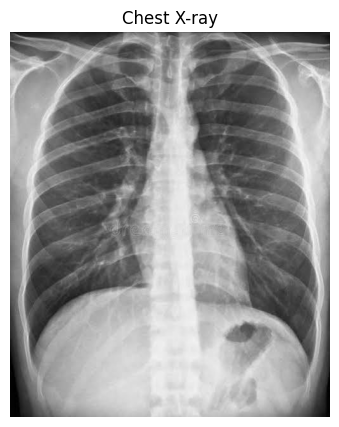

ANSWER:
 Based on the image provided, the following are visible:

*   The heart size appears within normal limits.
*   The mediastinum (the space in the chest between the lungs containing the heart, major blood vessels, trachea, etc.) appears unremarkable.
*   The lungs are generally clear, with no obvious consolidation (areas of dense opacity suggesting pneumonia) or large masses.
*   The ribs and clavicles are visible.
*   The diaphragm is visible at the bottom of the image.

There are no obvious abnormalities visible in this chest X-ray. However, it is important to note that subtle findings can be missed on a single image, and a definitive assessment requires evaluation by a qualified radiologist or doctor.

DISCLAIMER: This is an AI-generated response from an educational/research prototype. It is NOT a confirmed medical diagnosis and may be wrong. Please have the image reviewed by a qualified radiologist or doctor.

METADATA: {'model_id': 'google/medgemma-1.5-4b-it', 'language_code

In [13]:
import os
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from medvqa import answer_chest_xray, validate_image

SAMPLE_IMAGE_PATH = f"{PROJECT_DIR}/samples/chest_xray.png"

# Upload your downloaded chest X-ray
uploaded = files.upload()

filename = next(iter(uploaded))
SAMPLE_IMAGE_PATH = os.path.join(
    f"{PROJECT_DIR}/samples", filename
)

with open(SAMPLE_IMAGE_PATH, "wb") as f:
    f.write(uploaded[filename])

# Validate and display image
img, warns = validate_image(SAMPLE_IMAGE_PATH)
print("Image size:", img.size,
      "| validation warnings:", warns or "none")

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.title("Chest X-ray")
plt.show()

# Ask MedGemma a question
res = answer_chest_xray(
    SAMPLE_IMAGE_PATH,
    "What abnormalities, if any, are visible in this chest X-ray?"
)

print("ANSWER:\n", res["answer"])
print("\nDISCLAIMER:", res["disclaimer"])
print("\nMETADATA:", {
    k: v for k, v in res["metadata"].items()
    if k != "updated_history"
})

---
# ✅ Core pipeline works (if Step 7 gave a sensible answer). Everything below is the extended part.

## Step 8 — Structured test suite (question types + English / Hindi / Hinglish)

**Purpose:** run a fixed set of questions, record question, answer, runtime and errors to Drive, and test a follow-up question with conversation history. Multilingual behaviour is **observed, not assumed** — read the Hindi/Hinglish answers yourself (ideally have a fluent reader and a clinician review them).
**Expected output:** a table of results, and files `logs/test_results_<timestamp>.jsonl/.csv` in Drive. Total time ≈ (number of cases) × (seconds per answer).
**Common errors**
- One case shows an `error` string → that case failed but the loop continues; read the message (OOM → lower `max_new_tokens`).
- Hindi shown as boxes/garbled in the CSV when opened in Excel → the CSV is UTF-8 with BOM; open via *Data → From text* with UTF-8, or use the JSONL.

In [14]:
import json, datetime
import pandas as pd

# (case_id, question, language(None=auto), pivot_through_english)
TEST_CASES = [
    ("en_general",     "What abnormalities are visible in this chest X-ray?", None, False),
    ("en_effusion",    "Is there evidence suggestive of pleural effusion?", None, False),
    ("en_normal_check","Does this chest X-ray look normal, or is there any abnormality? Do not assume a finding exists.", None, False),
    ("en_explain",     "Can you explain the visible findings in simple language?", None, False),
    ("en_uncertainty", "Is this finding certain, or could there be other explanations?", None, False),
    ("hi_explain",     "कृपया इस chest X-ray में दिखाई देने वाली चीज़ों को आसान हिंदी में समझाइए।", None, False),
    ("hinglish_explain","Is chest X-ray mein kya dikh raha hai? Simple Hinglish mein samjhao.", None, False),
    ("hi_via_english", "कृपया इस chest X-ray में दिखाई देने वाली चीज़ों को आसान हिंदी में समझाइए।", None, True),
]

RUN_ID = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
records = []
for case_id, q, lang, pivot in TEST_CASES:
    rec = {"run_id": RUN_ID, "case_id": case_id, "question": q, "language_arg": lang, "pivot": pivot,
           "answer": None, "language_detected": None, "runtime_sec": None, "output_tokens": None,
           "warnings": None, "error": None, "reviewer_rating": "", "reviewer_notes": ""}
    try:
        res = answer_chest_xray(SAMPLE_IMAGE_PATH, q, language=lang, pivot_through_english=pivot)
        m = res["metadata"]
        rec.update(answer=res["answer"], language_detected=m["language_code"], runtime_sec=m["inference_time_sec"],
                   output_tokens=m["output_tokens"], warnings="; ".join(m["warnings"]))
    except Exception as e:  # keep going; record the failure
        rec["error"] = f"{type(e).__name__}: {e}"
    records.append(rec)
    print(f"[{case_id}] {rec['runtime_sec']}s  error={rec['error']}")

jsonl_path = f"{PROJECT_DIR}/logs/test_results_{RUN_ID}.jsonl"
with open(jsonl_path, "w", encoding="utf-8") as f:
    for r in records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")
df = pd.DataFrame(records)
df.to_csv(jsonl_path.replace(".jsonl", ".csv"), index=False, encoding="utf-8-sig")
print("\nSaved:", jsonl_path)

pd.set_option("display.max_colwidth", 200)
display(df[["case_id", "language_detected", "runtime_sec", "error"]])
for r in records:
    print("\n" + "=" * 90 + f"\n{r['case_id']}  |  Q: {r['question']}\n" + "-" * 90 + f"\n{r['answer'] or r['error']}")

[en_general] 14.33s  error=None
[en_effusion] 9.37s  error=None
[en_normal_check] 10.85s  error=None
[en_explain] 18.69s  error=None
[en_uncertainty] 29.11s  error=None
[hi_explain] 21.25s  error=None
[hinglish_explain] 21.29s  error=None
[hi_via_english] 78.59s  error=None

Saved: /content/drive/MyDrive/Medical_Chest_Xray_VQA/logs/test_results_20261020_145305.jsonl


,case_id,language_detected,runtime_sec,error
0,en_general,en,14.33,None
1,en_effusion,en,9.37,None
2,en_normal_check,en,10.85,None
3,en_explain,en,18.69,None
4,en_uncertainty,en,29.11,None
5,hi_explain,hi,21.25,None
6,hinglish_explain,hinglish,21.29,None
7,hi_via_english,hi,78.59,None



en_general  |  Q: What abnormalities are visible in this chest X-ray?
------------------------------------------------------------------------------------------
Based on the image provided, the following are visible:

*   The heart size appears within normal limits.
*   The mediastinum (the space between the lungs containing the heart, major blood vessels, trachea, etc.) appears unremarkable.
*   The lungs are generally clear, with no obvious consolidation (areas of dense opacity suggesting pneumonia) or large masses.
*   The ribs and clavicles are visible.
*   The diaphragm is visible at the bottom of the image.

There are no obvious abnormalities visible in this chest X-ray. However, subtle findings can be missed on a single image, and a definitive assessment requires evaluation by a qualified radiologist or doctor.

en_effusion  |  Q: Is there evidence suggestive of pleural effusion?
------------------------------------------------------------------------------------------
Based on

### Step 8b — Follow-up question with conversation history

Passes the previous exchange back as text; the image is re-attached once automatically, the system prompt is not repeated per turn. Remember the model card says MedGemma was **not evaluated for multi-turn use**, so check whether follow-ups stay consistent with the first answer.

In [15]:
first = answer_chest_xray(SAMPLE_IMAGE_PATH, "What abnormalities, if any, are visible in this chest X-ray?")
history = first["metadata"]["updated_history"]

follow = answer_chest_xray(SAMPLE_IMAGE_PATH, "Is this finding certain, or could there be other explanations?",
                           conversation_history=history)
print("FOLLOW-UP ANSWER:\n", follow["answer"])
print("\nwarnings:", follow["metadata"]["warnings"], "| time:", follow["metadata"]["inference_time_sec"], "s")
print("history length (messages):", len(follow["metadata"]["updated_history"]))

FOLLOW-UP ANSWER:
 Based on the image provided, the absence of obvious abnormalities is the most likely explanation. However, it is important to note that subtle findings can be missed on a single image, and a definitive assessment requires evaluation by a qualified radiologist or doctor.

warnings: [] | time: 8.4 s
history length (messages): 4


## Step 9 — Test with your own image (authorised, de-identified only)

**Purpose:** upload a PNG/JPEG chest X-ray and ask your own question.
**Privacy:** the file is saved to Colab's **temporary** disk (`/content/uploads`), *not* to Drive, and disappears when the runtime ends. Remove names, IDs, dates and burned-in text before uploading. DICOM files must be converted/de-identified first.
**Expected output:** the image, then the answer.
**Common errors:** `Unsupported image type` → convert to PNG/JPEG. `Image too small` → use the original resolution.

Saving images.jpg to images (1).jpg


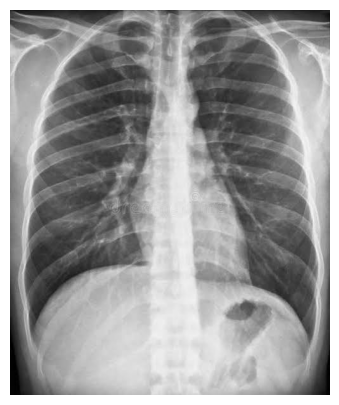

Based on the image provided, the following are visible:

*   The heart size appears within normal limits.
*   The mediastinum (the space between the lungs containing the heart, major blood vessels, trachea, etc.) appears unremarkable.
*   The lungs are generally clear, with no obvious consolidation (areas of dense opacity suggesting pneumonia) or large masses.
*   The ribs and clavicles are visible.
*   The diaphragm is visible at the bottom of the image.

There are no obvious abnormalities visible in this chest X-ray. However, subtle findings can be missed on a single image, and a definitive assessment requires evaluation by a qualified radiologist or doctor. 

 This is an AI-generated response from an educational/research prototype. It is NOT a confirmed medical diagnosis and may be wrong. Please have the image reviewed by a qualified radiologist or doctor. 

warnings: []


In [16]:
from google.colab import files

os.makedirs("/content/uploads", exist_ok=True)
uploaded = files.upload()          # choose ONE de-identified image
USER_IMAGE_PATH = None
for name, data in uploaded.items():
    USER_IMAGE_PATH = f"/content/uploads/{name}"
    with open(USER_IMAGE_PATH, "wb") as f:
        f.write(data)
    break

USER_QUESTION = "What abnormalities are visible in this chest X-ray?"   # <- edit me (English/Hindi/Hinglish)
USER_LANGUAGE = None                                                    # None = auto-detect

if USER_IMAGE_PATH:
    img, warns = validate_image(USER_IMAGE_PATH)
    plt.figure(figsize=(5, 5)); plt.imshow(img); plt.axis("off"); plt.show()
    res = answer_chest_xray(USER_IMAGE_PATH, USER_QUESTION, language=USER_LANGUAGE)
    print(res["answer"], "\n\n", res["disclaimer"], "\n\nwarnings:", res["metadata"]["warnings"])

## Step 10 — How to evaluate answer quality (without inventing scores)

I have **not** measured this model on any data, so this notebook contains **no accuracy numbers**. The model card reports its own benchmark results (e.g. MIMIC-CXR report generation RadGraph F1 27.2 for MedGemma 1.5 4B; VQA-RAD closed-set accuracy 70.2) — those are Google's numbers on specific datasets and do **not** describe your pipeline, prompts, or images.

**A defensible evaluation plan**
1. **Pick data you are allowed to use** and check each dataset's licence/data-use agreement (some, like MIMIC-CXR, need credentialed access). Prefer images *not* in the model's training data: the card lists MIMIC-CXR, Chest ImaGenome and SLAKE as training sources, so scores there are optimistic (the card itself warns about contamination).
2. **Reference answers must be reliable:** radiologist reports, or labels reviewed by a qualified clinician. Record who reviewed them.
3. **Closed (yes/no) questions** → accuracy, plus *sensitivity and specificity* per finding (accuracy alone hides false negatives). Cell below does this for a CSV you supply.
4. **Open-ended answers** → (a) blinded radiologist rating on accuracy, omissions, hallucinated findings and appropriate uncertainty; (b) optionally automatic metrics against reports (RadGraph F1, CheXbert-style label agreement) — these require extra tools and are only a proxy.
5. **Report separately:** normal-vs-abnormal images (does it over-call findings?), image quality, English vs Hindi vs Hinglish, and with/without `pivot_through_english`.
6. Keep a **held-out test set** untouched until the end; never tune prompts on it.

**CSV format for the closed-question cell** (`data/closed_eval.csv`, UTF-8): `image_path,question,reference_answer` where `reference_answer` is `yes` or `no`. The cell asks the model to answer yes/no and parses the first word; anything else is counted as "unclear" (reported separately, not silently counted as wrong or right).

**Common errors:** `FileNotFoundError` → create the CSV first (the cell writes a blank template). `0 usable rows` → paths in the CSV must be valid.

In [17]:
import re, csv, itertools

EVAL_CSV = f"{PROJECT_DIR}/data/closed_eval.csv"
if not os.path.exists(EVAL_CSV):
    with open(EVAL_CSV, "w", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow(["image_path", "question", "reference_answer"])
    print("Created empty template:", EVAL_CSV, "-> add reviewed rows, then rerun.")

def parse_yes_no(text):
    m = re.match(r"^\W*(yes|no)\b", text.strip().lower())
    return m.group(1) if m else "unclear"

def run_closed_eval(csv_path, model=None, processor=None, max_new_tokens=32, tag="base"):
    df = pd.read_csv(csv_path)
    rows = []
    for _, r in df.iterrows():
        q = str(r["question"]).strip() + " Answer with only 'Yes' or 'No', then one short sentence."
        try:
            out = answer_chest_xray(r["image_path"], q, max_new_tokens=max_new_tokens, model=model, processor=processor)
            pred = parse_yes_no(out["answer"])
        except Exception as e:
            pred = "error"
        rows.append({"image_path": r["image_path"], "question": r["question"],
                     "reference": str(r["reference_answer"]).strip().lower(), "prediction": pred})
    res = pd.DataFrame(rows)
    if res.empty:
        print("0 usable rows."); return res
    answered = res[res.prediction.isin(["yes", "no"])]
    tp = ((answered.reference == "yes") & (answered.prediction == "yes")).sum()
    tn = ((answered.reference == "no") & (answered.prediction == "no")).sum()
    fp = ((answered.reference == "no") & (answered.prediction == "yes")).sum()
    fn = ((answered.reference == "yes") & (answered.prediction == "no")).sum()
    print(f"[{tag}] n={len(res)} | answered={len(answered)} | unclear={(res.prediction=='unclear').sum()} | errors={(res.prediction=='error').sum()}")
    print(f"  TP={tp} TN={tn} FP={fp} FN={fn}")
    if len(answered):
        print(f"  accuracy={(tp+tn)/len(answered):.3f}  sensitivity={tp/max(tp+fn,1):.3f}  specificity={tn/max(tn+fp,1):.3f}")
    res.to_csv(f"{PROJECT_DIR}/logs/closed_eval_{tag}_{datetime.datetime.now():%Y%m%d_%H%M%S}.csv", index=False)
    return res

if len(pd.read_csv(EVAL_CSV)) > 0:
    _ = run_closed_eval(EVAL_CSV)
else:
    print("No rows in", EVAL_CSV, "- nothing to evaluate yet (and no scores are invented).")

Created empty template: /content/drive/MyDrive/Medical_Chest_Xray_VQA/data/closed_eval.csv -> add reviewed rows, then rerun.
No rows in /content/drive/MyDrive/Medical_Chest_Xray_VQA/data/closed_eval.csv - nothing to evaluate yet (and no scores are invented).


## Step 11 — Save the project (and, optionally, the model) to Google Drive — with verification

**Three different things people mean by "saving":**
| What | Size | Notes |
|---|---|---|
| The **notebook** | KB | `File → Save a copy in Drive`. Colab cannot reliably do this from code; do it manually. |
| **Code + config + logs** (this project) | KB–MB | Already in Drive from Steps 3–8. Cell below verifies it. |
| **Model weights** | ≈ 8–9 GB (bf16) | Original, un-fine-tuned weights can always be re-downloaded from Hugging Face. A Drive copy only saves download time. |
| **Fine-tuned checkpoint** (LoRA adapter) | ≈ tens–hundreds of MB | Only exists if you run the optional Step 13; **this** is the thing that is unique to you and worth saving. |

⚖️ **Licence:** use is governed by the HAI-DEF terms. I did not verify their exact redistribution wording, so **read them** before sharing any model copy with anyone else. The safest default: do not re-upload or share weights — let each user accept the terms and download from Hugging Face. The optional copy below goes only into *your own* Drive folder.

**Expected output:** a verification table that ends in `✅ PROJECT FILES VERIFIED`. The model copy is only claimed as saved if the size/file checks pass.
**Common errors:** `Not enough Drive space` → free ≥ 12 GB or keep `SAVE_MODEL_COPY = False` (default; reload from Hugging Face next time). Don't save a 4-bit model this way (the cell blocks it).

In [18]:
import json, glob, datetime

# 1) Project config (always)
config = {
    "model_id": MODEL_ID,
    "loaded_in_4bit": bool(use_4bit),
    "saved_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "generation": {"do_sample": False, "default_max_new_tokens": 512},
    "notes": "Educational/research prototype. Not a medical device.",
}
with open(f"{PROJECT_DIR}/project_config.json", "w") as f:
    json.dump(config, f, indent=2)

# 2) Verify code/config/log files really exist and are non-empty
expected = ["src/medvqa/__init__.py", "src/medvqa/config.py", "src/medvqa/inference.py",
            "requirements.txt", "project_config.json"]
ok = True
for rel in expected:
    p = f"{PROJECT_DIR}/{rel}"
    size = os.path.getsize(p) if os.path.exists(p) else -1
    status = "OK " if size > 0 else "MISSING"
    ok &= size > 0
    print(f"{status} {rel:32s} {size:>8} bytes")
print("Logs saved:", len(glob.glob(f"{PROJECT_DIR}/logs/*")), "file(s)")
print("✅ PROJECT FILES VERIFIED" if ok else "❌ Some project files are missing - rerun Steps 3-5.")

# 3) OPTIONAL: full model copy in Drive (off by default)
SAVE_MODEL_COPY = False
MODEL_COPY_DIR = f"{PROJECT_DIR}/model_copy/medgemma-1.5-4b-it"

if SAVE_MODEL_COPY:
    free_gb = shutil.disk_usage(PROJECT_DIR).free / 1024**3
    if use_4bit:
        print("❌ Model is loaded in 4-bit; saving that is not what you want. Reload in bf16 first.")
    elif free_gb < 12:
        print(f"❌ Not enough Drive space ({free_gb:.1f} GB free, need ~12 GB).")
    else:
        os.makedirs(MODEL_COPY_DIR, exist_ok=True)
        model.save_pretrained(MODEL_COPY_DIR, safe_serialization=True)
        processor.save_pretrained(MODEL_COPY_DIR)
        files_ = sorted(os.listdir(MODEL_COPY_DIR))
        total_gb = sum(os.path.getsize(f"{MODEL_COPY_DIR}/{x}") for x in files_) / 1024**3
        has_cfg = "config.json" in files_
        has_w = any(x.endswith(".safetensors") for x in files_)
        print("Files:", files_); print(f"Total size: {total_gb:.2f} GB")
        if has_cfg and has_w and total_gb > 6:
            with open(f"{MODEL_COPY_DIR}/VERIFIED.txt", "w") as f:
                f.write(f"Saved {datetime.datetime.now().isoformat()} | {total_gb:.2f} GB | from {MODEL_ID}\n")
            print("✅ Model copy saved and file checks passed (to fully prove it, reload it with load_model(local_path=...)).")
        else:
            print("❌ Model copy INCOMPLETE - do not rely on it.")
else:
    print("\nModel copy skipped (SAVE_MODEL_COPY=False). To reload the original model in a future session: "
          "run Steps 1-4, then medvqa.load_model().")

OK  src/medvqa/__init__.py                407 bytes
OK  src/medvqa/config.py                 3755 bytes
OK  src/medvqa/inference.py             16145 bytes
OK  requirements.txt                      224 bytes
OK  project_config.json                   258 bytes
Logs saved: 2 file(s)
✅ PROJECT FILES VERIFIED

Model copy skipped (SAVE_MODEL_COPY=False). To reload the original model in a future session: run Steps 1-4, then medvqa.load_model().


In [20]:
import os

print("Model available:", "model" in globals())
print("Processor available:", "processor" in globals())

if "medvqa" in globals():
    print("MedVQA attributes:", [
        name for name in dir(medvqa)
        if "model" in name.lower() or "processor" in name.lower()
    ])

print("Drive folder exists:", os.path.exists(
    "/content/drive/MyDrive/Medical_Chest_Xray_VQA/model_copy"
))

Model available: True
Processor available: True
MedVQA attributes: ['MODEL_ID', 'load_model', 'set_model']
Drive folder exists: True
